# Maze Solver — Search Algorithms

This project explores how different search algorithms find a path from a **Start** cell to a **Goal** cell in a maze. The idea is inspired by the **Search** topic in [CS50's Introduction to Artificial Intelligence with Python (CS50 AI)](https://cs50.harvard.edu/ai/), where a problem is represented as a set of states and the actions that move us between them.

The project compares three search strategies: **Depth-First Search (DFS)**, **Breadth-First Search (BFS)**, and **A* Search**. Each algorithm is visualized while it explores the maze, allowing us to compare not only the final paths but also the exploration process.

## 1. Maze Representation

The maze is represented as a two-dimensional grid. Each cell is encoded using an integer:

| Value | Meaning |
|:---:|---|
| `0` | Empty — a traversable cell |
| `1` | Wall — an obstacle that cannot be crossed |
| `2` | Start — the starting position |
| `3` | Goal — the target position |
| `4` | Final Path — a cell belonging to the path found by the algorithm |
| `5` | Explored — a cell that has been examined by the algorithm |

From each cell, the algorithm can move to one of its four direct neighbors: up, down, left, or right. Diagonal movement is not allowed, and every move has the same cost.

## 2. The Core Idea: How Search Works

A search algorithm starts at the initial cell and maintains a collection of discovered cells that have not yet been explored. This collection is called the **Frontier**.

At each iteration, the algorithm selects a cell from the Frontier and examines its neighbors. Walls and out-of-bounds positions are ignored. The algorithm then decides whether each valid neighbor should be added to the Frontier.

The implementations use:

- **Frontier:** Stores the cells waiting to be explored.
- **Visited:** Used by DFS and BFS to prevent repeatedly exploring discovered cells.
- **g_score:** Used by A* to store the lowest known cost from the start to each cell. A cell can be reconsidered if a shorter path to it is found.
- **Parent:** Records the predecessor of each cell. These relationships are followed backward to reconstruct the final path.
- **Visualization:** Updates the cell colors during the search so the exploration process can be observed step by step.

The main difference between these algorithms is **how they select the next cell from the Frontier**.

## 3. Comparing Search Algorithms

| Algorithm | Frontier selection strategy | Guarantees the shortest path? | Main idea |
|---|---|---|---|
| **DFS** — Depth-First Search | Most recently added cell (LIFO / Stack) | No | Follows one path as deeply as possible before backtracking. |
| **BFS** — Breadth-First Search | Earliest added cell (FIFO / Queue) | Yes, when every move has the same cost | Explores the maze level by level. |
| **A\*** — A-Star Search | Lowest estimated total path cost, `f(n) = g(n) + h(n)` | Yes, with an admissible heuristic and a correct implementation | Considers both the cost already spent and the estimated remaining cost. |

### DFS — Depth-First Search

DFS uses a **stack** (LIFO). It explores the most recently discovered cell first, following one branch as far as possible before trying alternatives.

- It does not guarantee the shortest path.
- It can reach the goal quickly if it chooses a good branch.
- It can also spend time exploring a long, unpromising branch.
- Its memory usage is often lower than BFS in tree-search settings, but this is not guaranteed for every maze or implementation.

### BFS — Breadth-First Search

BFS uses a **queue** (FIFO). It explores all cells one move away from the start before exploring cells two moves away, and so on.

- It guarantees the shortest path when all moves have equal cost.
- It may explore many cells that are not on the final path.
- It can require substantial memory because the Frontier may become very large.

### A* — A-Star Search

A* uses a **priority queue**, implemented with Python's `heapq`, instead of a regular stack or queue. It prioritizes cells using:

$$
f(n)=g(n)+h(n)
$$

where:

- `g(n)` is the actual cost of the path from the start to the current cell.
- `h(n)` is the estimated cost from the current cell to the goal.
- `f(n)` is the estimated total cost of a path through the current cell.

For this maze, movement is restricted to horizontal and vertical directions, so **Manhattan Distance** is a suitable heuristic:

$$
h(n)=|x_n-x_{goal}|+|y_n-y_{goal}|
$$

This heuristic estimates the minimum number of moves to the goal if there were no walls. It never overestimates the true remaining distance, making it **admissible**.

**How the implementation works:**

1. Every cell starts with a `g_score` of infinity, except the starting cell, whose cost is zero.
2. The priority queue stores entries containing the estimated total cost, the actual steps taken, and the cell coordinates.
3. When a cell is explored, its neighbors are evaluated. Their `g_score` values and parents are updated only if a shorter path is found.
4. The algorithm skips outdated priority-queue entries when a better path to the same cell has already been discovered.
5. Once the goal is removed from the priority queue, the `parent` dictionary is used to reconstruct the final path.

Unlike Greedy Best-First Search, which prioritizes only the estimated distance to the goal, A* considers both the actual cost already incurred and the estimated remaining cost.

With Manhattan Distance and equal movement costs, this implementation finds an optimal shortest path.

### Memory and Search Behavior

It is common to say that DFS uses less memory than BFS, but the comparison depends on the search space and implementation. In tree search, DFS typically uses `O(bm)` space, while BFS uses `O(b^d)`, where `b` is the branching factor, `m` is the maximum depth, and `d` is the depth of the shallowest solution.

In this grid implementation, the algorithms also store explored cells and parent relationships. A* additionally maintains a `g_score` grid and a priority queue. Therefore, actual memory usage depends on the number of discovered cells and the data structures used.

## 4. What Are We Trying to Observe?

The goal is to compare more than whether an algorithm can reach the goal:

1. The order in which each algorithm explores cells.
2. The number of cells explored before reaching the goal.
3. The length of the final path.
4. The amount of memory required during the search.

The visualizations help demonstrate an important distinction: **finding a path does not necessarily mean finding the shortest path**. DFS, BFS, and A* approach this problem in different ways, and their behavior becomes easier to understand when their exploration processes are viewed side by side.

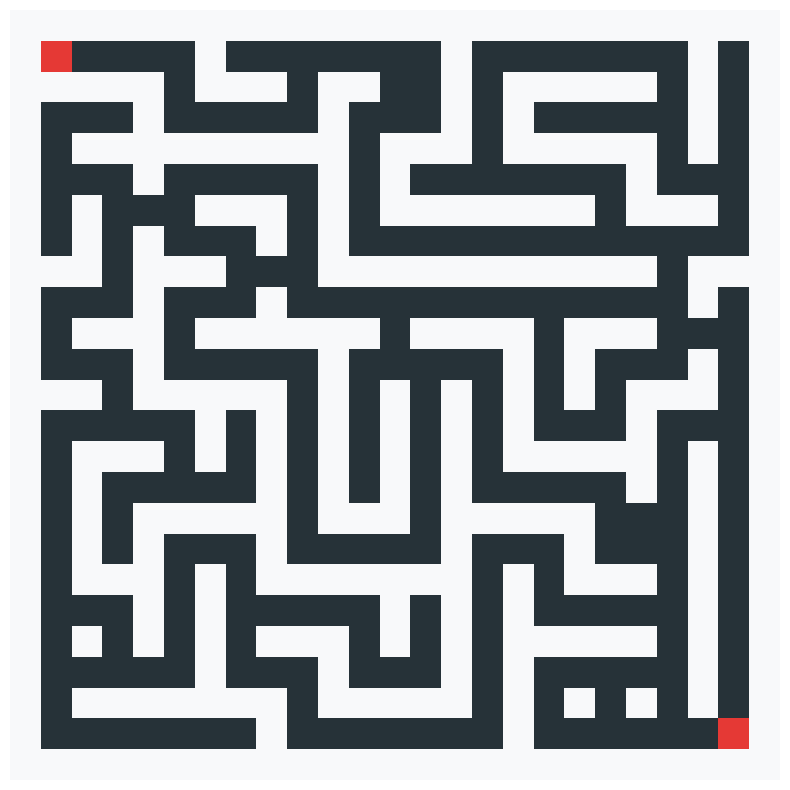

In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from time import sleep


# dfs
maze_one = [
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
]

# bfs
maze_two = [
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 3, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
]

# A*
maze_there = [
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1],
    [1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1],
    [1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
]

selected_maze = maze_two

def create_maze(maze):

    # Create the figure and axes used to display the maze.
    fig, ax = plt.subplots(figsize=(10, 10))

    # Assign a specific color to each cell value in the maze.
    colors = ListedColormap([
    '#263238',  # 0: Empty
    '#F8F9FA',  # 1: Wall
    '#E53935',  # 2: Start
    '#E53935',  # 3: Goal
    '#2E7D32',  # 4: Final Path
    '#E6A817',  # 5: Visited
    ])

    # Hide axis ticks, labels, and borders to display only the maze.
    ax.axis('off')

    # Render the maze as an image using the defined color mapping.
    img = ax.imshow(maze, cmap=colors, vmin=0, vmax=5)

    # Display the figure and create a handle that allows updating it later.
    handle = display(fig, display_id=True)

    # Prevent Matplotlib from displaying the same figure again automatically.
    plt.close(fig)


    def update_maze(updated_maze : list[list[int]]) -> None:

        # Update the existing image instead of creating a new figure each time.
        img.set_data(updated_maze)

        # Refresh the displayed figure with the updated maze.
        handle.update(fig) # type: ignore

        # Add a short delay so each visualization step can be observed.
        sleep(.05)

    return update_maze

# Display the initial state of the maze.

update_maze = create_maze(selected_maze)

update_maze(selected_maze)

## 5. DFS and BFS: Search Implementation and Visualization

The following cell implements DFS and BFS using the same search logic and a `deque` as the Frontier.

The difference is the operation used to remove the next cell:

- **BFS:** `popleft()` removes the oldest cell, following FIFO order.
- **DFS:** `pop()` removes the newest cell, following LIFO order.

Keeping the rest of the implementation shared makes it easier to observe how the Frontier strategy changes the exploration process.

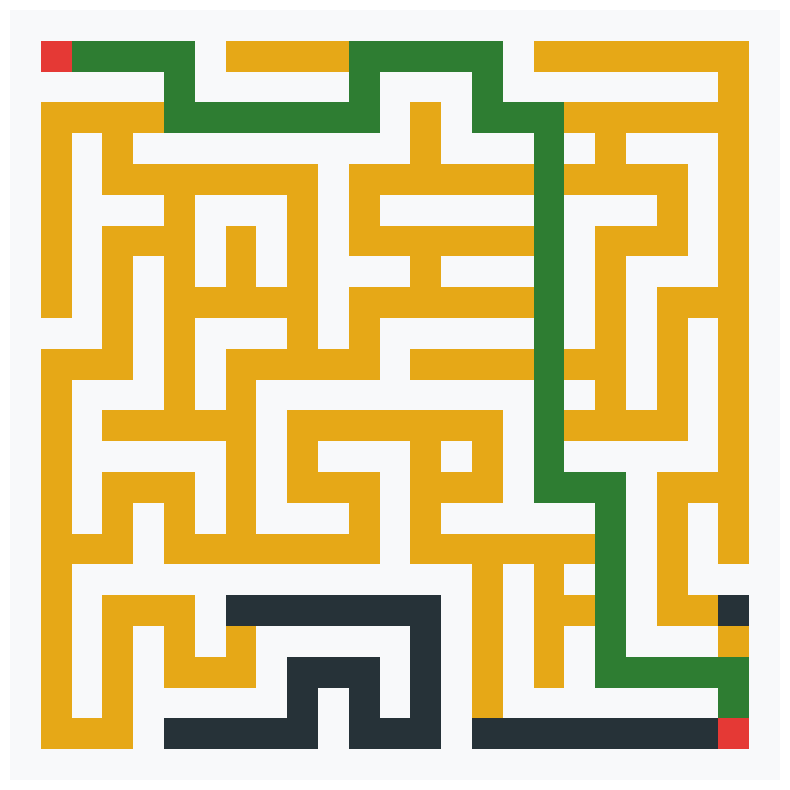

In [9]:
from collections import deque

maze = [row.copy() for row in selected_maze]

update_maze = create_maze(maze)

def solve_maze(start, search_type):

    n, m = len(maze), len(maze[0])

    frontier = deque([start])  # Cells waiting to be explored.

    parent = {}  # Store each cell's predecessor to reconstruct the path.

    visited = {start}  # Prevent revisiting cells.

    while frontier:

        # BFS explores the oldest cell; DFS explores the newest one.
        i, j = frontier.popleft() if search_type == "bfs" else frontier.pop()

        neighbors = [(i + 1, j), (i - 1, j), (i, j + 1), (i, j - 1)]

        for x, y in neighbors:

            # Skip out-of-bounds cells, walls, and previously visited cells.
            if not 0 <= x < n or not 0 <= y < m or maze[x][y] == 1 or (x, y) in visited:

                continue

            parent[(x, y)] = (i, j)

            if maze[x][y] == 3:  # Goal Has Been Found

                # Trace predecessors backward to reconstruct the path to the start
                node = parent[(x, y)]

                while node != start:

                    maze[node[0]][node[1]] = 4

                    node = parent[node]

                return True

            maze[x][y] = 5  # Mark the cell as explored.

            frontier.append((x, y))

            visited.add((x, y))

            update_maze(maze)

    return False


sleep(2)

solve_maze(start=(1, 1), search_type="bfs")

update_maze(maze)

## 6. A* Search: Priority-Based Exploration

Unlike DFS and BFS, A* does not use a simple FIFO queue or LIFO stack. It uses a **priority queue**, implemented here with Python's `heapq`, to select the cell with the lowest estimated total cost.

The priority is calculated using:

$$
f(n)=g(n)+h(n)
$$

For this grid:

- `g(n)` represents the actual number of moves taken from the start to reach the current cell.
- `h(n)` is the Manhattan Distance from the current cell to the goal.
- `f(n)` represents the estimated total cost of a path through the current cell.

The Manhattan heuristic is appropriate because movement is limited to four directions and every move has a cost of one.

**How the implementation works:**

1. Each cell is assigned an initial `g_score` of infinity, except for the starting cell, which has a cost of zero.
2. The priority queue stores cells according to their estimated total cost, `g(n) + h(n)`.
3. Whenever a cell is explored, its neighbors are evaluated, and their `g_score` values are updated only when a shorter path is found.
4. The `parent` dictionary stores the predecessor of each cell, allowing the final path to be reconstructed once the goal is reached.
5. Outdated entries in the priority queue are skipped to avoid processing paths that are no longer optimal.

Unlike Greedy Best-First Search, which prioritizes only the estimated distance to the goal, A* considers both the cost already incurred and the estimated remaining cost.

With an admissible heuristic such as Manhattan Distance in this grid, A* guarantees an optimal shortest path.

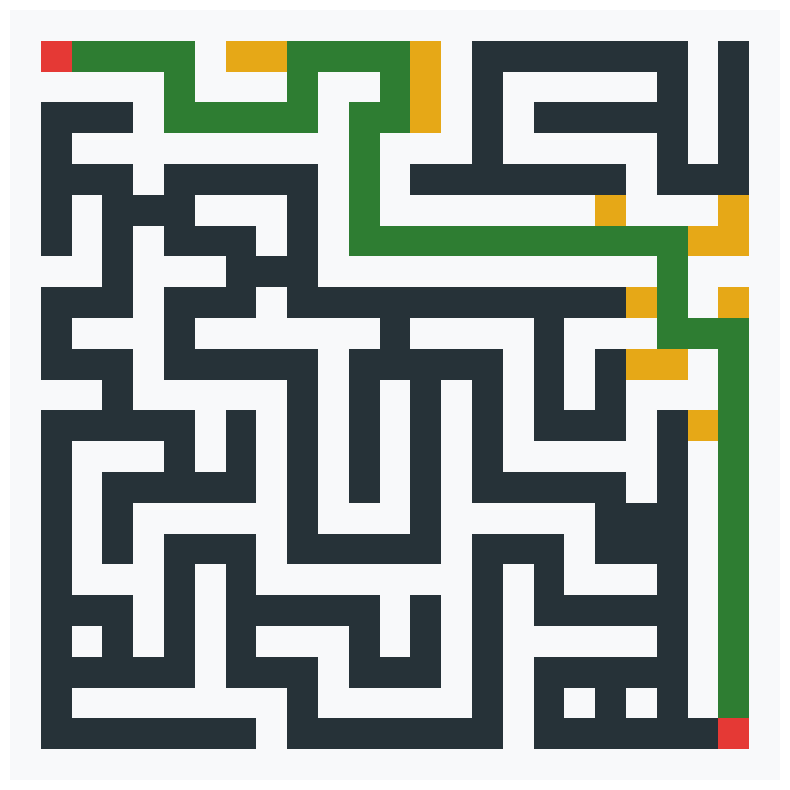

In [13]:
import heapq

maze = [row.copy() for row in selected_maze]

update_maze = create_maze(maze)

def A_star(start, end):

        n, m = len(maze), len(maze[0])

        # Manhattan distance: estimated cost from each cell to the goal.
        distances = [
            [abs(x - end[0]) + abs(y - end[1]) for y in range(m)] for x in range(n)
        ]

        # Priority queue: (estimated total cost, steps taken, current cell).
        frontier = [[distances[start[0]][start[1]], 0, start]]

        # Best known number of steps required to reach each cell.
        g_score = [[float("inf") for _ in range(m)] for _ in range(n)]

        g_score[start[0]][start[1]] = 0

        parent = {}  # Store each cell's predecessor to reconstruct the path.

        while frontier:

            total_cost, num_of_steps, (i, j) = heapq.heappop(frontier)

            if num_of_steps != g_score[i][j]:
                continue

            neighbors = [(i - 1, j), (i + 1, j), (i, j - 1), (i, j + 1)]

            if (i, j) == end:  # Goal Has Been Reached

                maze[i][j] = 3

                # Trace predecessors backward to reconstruct the path to the start
                node = parent[(i, j)]

                while node != start:

                    maze[node[0]][node[1]] = 4

                    node = parent[node]

                return True

            for x, y in neighbors:

                # Skip out-of-bounds cells, walls, and previously visited cells.
                if (
                    not 0 <= x < n
                    or not 0 <= y < m
                    or maze[x][y] == 1
                    or g_score[x][y] <= (num_of_steps + 1)
            ):
                    continue

                g_score[x][y] = num_of_steps + 1

                maze[x][y] = 5  # Mark the cell as explored.

                parent[(x, y)] = (i, j)

                # Calculate f(n) = g(n) + h(n) and add the cell to the priority queue.
                heapq.heappush(
                    frontier, [distances[x][y] + num_of_steps + 1, num_of_steps + 1, (x, y)]
                )

                update_maze(maze)

        return False


sleep(2)

A_star(start=(1, 1), end=(23, 23))

update_maze(maze)